In [ ]:
# Path setup: lets the notebook run from anywhere inside the repo
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
DATA = ROOT / "data"
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "supervisor_code")]

In [1]:
from classes import *
from functions import *
from utils import *
from metrics import *
import seaborn as sns
import statsmodels.tsa as sm
import statsmodels.api as sma
import matplotlib.pyplot as plt
import pickle
import warnings
%load_ext autoreload
%autoreload 2
pd.set_option('display.max_columns', None)

In [2]:
data = pd.read_excel(DATA / 'data.xlsx')
new_header = data.iloc[1]
description = data.iloc[0]
data = data[2:]
data.columns = new_header
data.set_index('Dates', inplace=True)
data.index = pd.to_datetime(data.index)
data.sort_index(inplace=True)
data = data.astype(float)

/Users/Jules/Desktop/MS-ARCH-X/MS-ARCHX/venv/lib/python3.9/site-packages/pandas/core/indexes/base.py:7616: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


In [54]:
import pandas as pd

target_index = 'SPX Index'


df = pd.read_excel(DATA / "data.xlsx", skiprows=2)  # Skip first two header rows
#df = df[['Dates', target_index]] # Choose these 2 columns
#df.columns = ['Date', target_index]  # Clean column names

df = df[['Dates', 'SPX Index', 'VIX Index', 'CAC Index' ]]  # Use both indices
df.columns = ['Date', 'SPX Index', 'VIX Index', 'CAC Index']  # Clean column names



# Convert to datetime if not already
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Define your regime periods
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]

# === Step 3: Group periods for plotting ===
regimes = ["Stability", "Crisis", "Recovery"]
regime_groups = {regime: [] for regime in regimes}

#problem periods : ("2022-01-01", "2022-10-12", "Crisis"), # 0 for alpha1
    #("2009-04-01", "2010-12-31", "Recovery") # 0 for alpha1

# Function to assign regime

# Function to assign regime
def assign_regime(date):
    for start, end, regime in regime_periods:
        if pd.Timestamp(start) <= date <= pd.Timestamp(end):
            return regime
    return "Unclassified"

# Apply regime classification
df['Regime'] = df['Date'].apply(assign_regime)

# Save to new Excel file
df.to_excel(DATA / "SPX_with_regimes.xlsx", index=False)

In [55]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "notebook"


# Load your labeled file
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
#df['Log Return'] = np.log(df['SPX Index'] / df['SPX Index'].shift(1))
df['Return'] = df['SPX Index'] 


# Drop first row with NaN
df = df.dropna(subset=['Return'])

# Insert NaNs where regime changes
df['Regime Shift'] = (df['Regime'] != df['Regime'].shift(1)).astype(int).cumsum()
df['Return Clean'] = df['Return']  # Will insert NaNs between regime blocks

# Detect non-contiguous groups and insert NaNs to break lines
df['Block ID'] = df['Regime'] + '_' + df['Regime Shift'].astype(str)

# Plot using block ID as line group
fig = px.line(
    df,
    x='Date',
    y='Return Clean',
    color='Regime',
    line_group='Block ID',
    title='S&P 500 Returns (1990–2025) with Regimes',
    labels={'Return Clean': 'Return'},
    template='plotly_white'
)

fig.update_layout(
    xaxis_title='Date',
    yaxis_title='Return',
    legend_title='Regime',
    hovermode='x unified',
    font=dict(size=14)
)

fig.show()


In [5]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "notebook"


# Use Log returns bc additive over time (sum of daily log returns over a month approximates the monthly log return) --> COMPARABLE over regimes
#--> Compare the volatility of Crisis vs. Recovery on an equal basis
# Crisis are more sharp : look at 2k20, Covid

#Crisis regimes, volatility is higher + longer tails and more frequent extreme events.
#Recovery periods : medium volatility but upward momentum
#Stability : by low, symmetric

#3 regime de vol pas intéressant

# Load your labeled file
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
df['Log Return'] = np.log(df['SPX Index'] / df['SPX Index'].shift(1))
#df['Log Return'] = df['SPX Index'] 


# Drop first row with NaN
df = df.dropna(subset=['Log Return'])

# Insert NaNs where regime changes
df['Regime Shift'] = (df['Regime'] != df['Regime'].shift(1)).astype(int).cumsum()
df['Log Return Clean'] = df['Log Return']  # Will insert NaNs between regime blocks

# Detect non-contiguous groups and insert NaNs to break lines
df['Block ID'] = df['Regime'] + '_' + df['Regime Shift'].astype(str)

# Plot using block ID as line group
fig = px.line(
    df,
    x='Date',
    y='Log Return Clean',
    color='Regime',
    line_group='Block ID',
    title='S&P 500 Log Returns (1990–2025) with Regimes',
    labels={'Log Return Clean': 'Log Return'},
    template='plotly_white'
)

fig.update_layout(
    xaxis_title='Date',
    yaxis_title='Log Return',
    legend_title='Regime',
    hovermode='x unified',
    font=dict(size=14)
)

fig.show()


In [ ]:
#Applying a Model ARCH(1) to each period

from arch import arch_model
import pandas as pd

# Assuming 'df' contains columns: ['Date', 'Return', 'Regime'] and is OK
# 'regime_periods' defined as before

results = []

df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')


#df['Return'] = df['SPX Index'].pct_change() #compute the return (not percentage for now)

df['Return'] = np.log(df['SPX Index']).diff() #if we want log returns, using diff of log, instead, useful for arch models



for start, end, label in regime_periods:
    # Step 1: Create weight mask as we said we should
    mask = (df['Date'] >= pd.Timestamp(start)) & (df['Date'] <= pd.Timestamp(end)) #Weight 0
    df['Weight'] = mask.astype(int)

    # Step 2: Extract all relevant returns
    #returns = df.loc[mask, 'Return'] * 100  # put percentage returns
    returns = df.loc[mask, 'Return'].dropna() * 100
    
    if len(returns) < 100: #VOIR QUEL LIMITE METTRE ICI
        print(f"Skipping {label} ({start}–{end}) — too few returns: {len(returns)}")
        continue

    # Step 3: Fit ARCH(1)
    am = arch_model(returns, vol='ARCH', p=1, mean='Constant',dist='normal', rescale=False)  #remettre normal
    fit = am.fit(disp='off')
    #returns["Volatility"] = fit.conditional_volatility
    #regime_groups[regime].append((start, end, returns))

    # Step 4: Store results
    params = fit.params
    print(params)
    results.append({
        'Start': start,
        'End': end,
        'Regime': label,
        'mu': params.get('mu', None),
        'alpha0': params.get('omega'),       # this is α₀
        'alpha1': params.get('alpha[1]')     # this is α₁

    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

#print(params)
#print(results_df)


mu          0.058642
omega       0.682296
alpha[1]    0.194357
Name: params, dtype: float64
mu         -0.075930
omega       1.717747
alpha[1]    0.171569
Name: params, dtype: float64
mu          0.071472
omega       1.054556
alpha[1]    0.202193
Name: params, dtype: float64
mu          0.035608
omega       0.498986
alpha[1]    0.040215
Name: params, dtype: float64
mu         -0.155036
omega       4.738495
alpha[1]    0.227498
Name: params, dtype: float64
mu          0.103655
omega       1.459872
alpha[1]    0.000000
Name: params, dtype: float64
mu          0.054626
omega       0.610904
alpha[1]    0.253826
Name: params, dtype: float64
Skipping Crisis (2020-02-18–2020-03-24) — too few returns: 26
mu          0.204352
omega       0.833269
alpha[1]    0.675927
Name: params, dtype: float64
mu          0.091721
omega       0.609290
alpha[1]    0.242376
Name: params, dtype: float64
mu         -0.147185
omega       2.316986
alpha[1]    0.000000
Name: params, dtype: float64
mu          0.1628

In [ ]:
from IPython.display import display
display(results_df)

#results_df.to_excel(DATA / "ARCH_results_by_period.xlsx", index=False)

,Start,End,Regime,mu,alpha0,alpha1
0,1990-01-01,2000-03-31,Stability,0.058642,0.682296,0.194357
1,2000-04-01,2002-09-30,Crisis,-0.075930,1.717747,0.171569
2,2002-10-01,2004-03-31,Recovery,0.071472,1.054556,0.202193
3,2004-04-01,2007-10-31,Stability,0.035608,0.498986,0.040215
4,2007-11-01,2009-03-31,Crisis,-0.155036,4.738495,0.227498
5,2009-04-01,2010-12-31,Recovery,0.103655,1.459872,0.000000
6,2011-01-01,2020-02-17,Stability,0.054626,0.610904,0.253826
7,2020-03-25,2021-09-15,Recovery,0.204352,0.833269,0.675927
8,2020-09-16,2021-12-31,Stability,0.091721,0.609290,0.242376
9,2022-01-01,2022-10-12,Crisis,-0.147185,2.316986,0.000000


mu              alpha0              alpha1          
               mean       std      mean       std      mean       std
Regime                                                               
Crisis    -0.126050  0.043582  2.924409  1.599360  0.133022  0.118546
Recovery   0.135571  0.059441  1.062787  0.280363  0.277821  0.284832
Stability  0.064385  0.022308  0.592535  0.067839  0.166658  0.092467

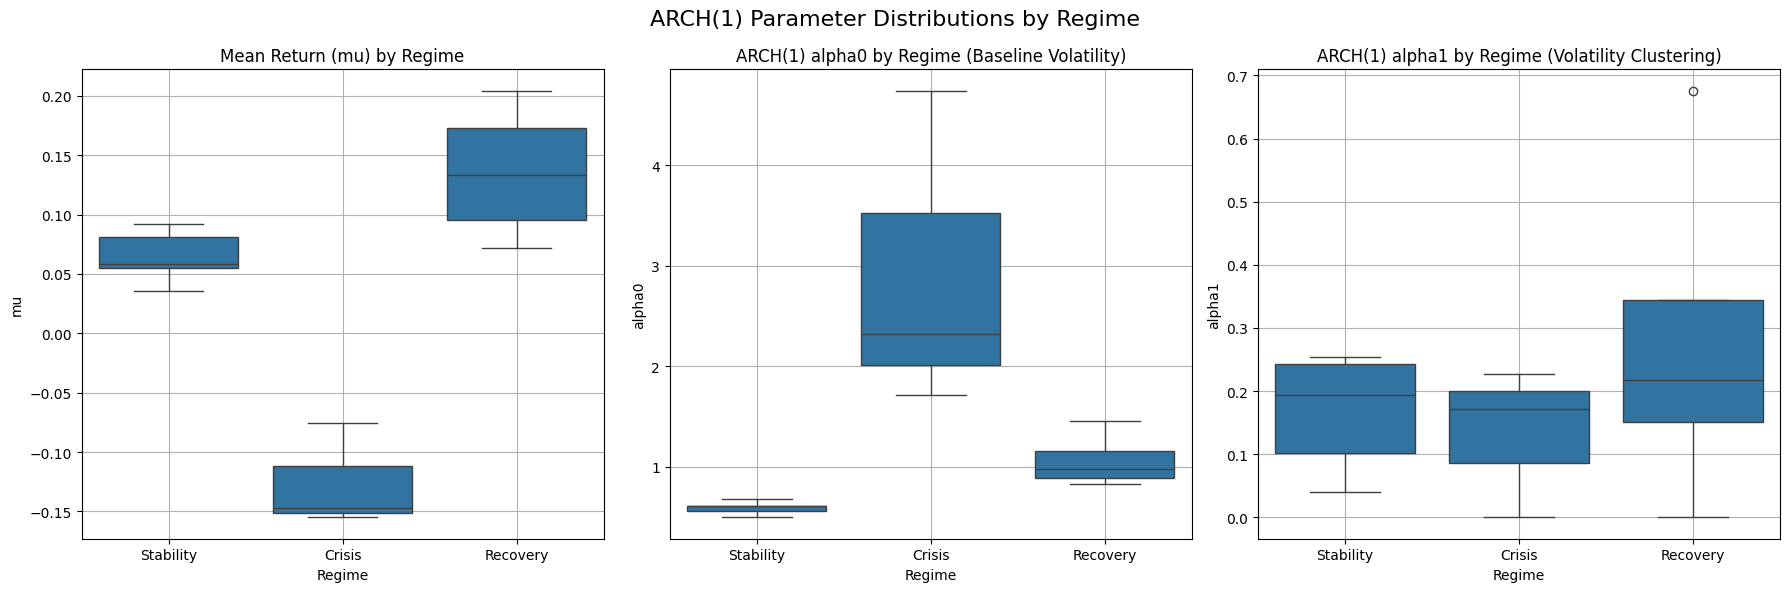

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# T bars are the "whiskers", Any data points outside that range are considered outliers.
#Blue box represents the “middle 50%” of the data
#median line
#outliers are the dots
#--> Using IQR for blue box and T bars and outsiders : IQR = (all point btw quartile 1 and 3)

# OPTIONAL: Only if loading from file
# results_df = pd.read_excel(DATA / "ARCH_results_by_period.xlsx")

# Drop rows with missing parameters, there shouldn't be any
#filtered_df = results_df.dropna(subset=["mu", "alpha0", "alpha1"])
filtered_df = results_df

# Step 2: Group by Regime and calculate mean and std for each parameter
group_stats = filtered_df.groupby("Regime")[["mu", "alpha0", "alpha1"]].agg(["mean", "std"])


# Display group statistics
display(group_stats)

# Step 3: Plot boxplots to compare distributions by regime
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

sns.boxplot(data=filtered_df, x="Regime", y="mu", ax=axs[0])
axs[0].set_title("Mean Return (mu) by Regime")
axs[0].set_ylabel("mu")
axs[0].grid(True)

sns.boxplot(data=filtered_df, x="Regime", y="alpha0", ax=axs[1])
axs[1].set_title("ARCH(1) alpha0 by Regime (Baseline Volatility)")
axs[1].set_ylabel("alpha0")
axs[1].grid(True)

sns.boxplot(data=filtered_df, x="Regime", y="alpha1", ax=axs[2])
axs[2].set_title("ARCH(1) alpha1 by Regime (Volatility Clustering)")
axs[2].set_ylabel("alpha1")
axs[2].grid(True)

plt.suptitle("ARCH(1) Parameter Distributions by Regime", fontsize=16)
plt.tight_layout()
plt.show()


⚠️ Skipping Crisis 2020-02-18 to 2020-03-24 — too few returns: 26
⚠️ Skipping Stability 2025-01-01 to 2025-02-20 — too few returns: 34
⚠️ Skipping Crisis 2025-02-20 to 2025-04-30 — too few returns: 45


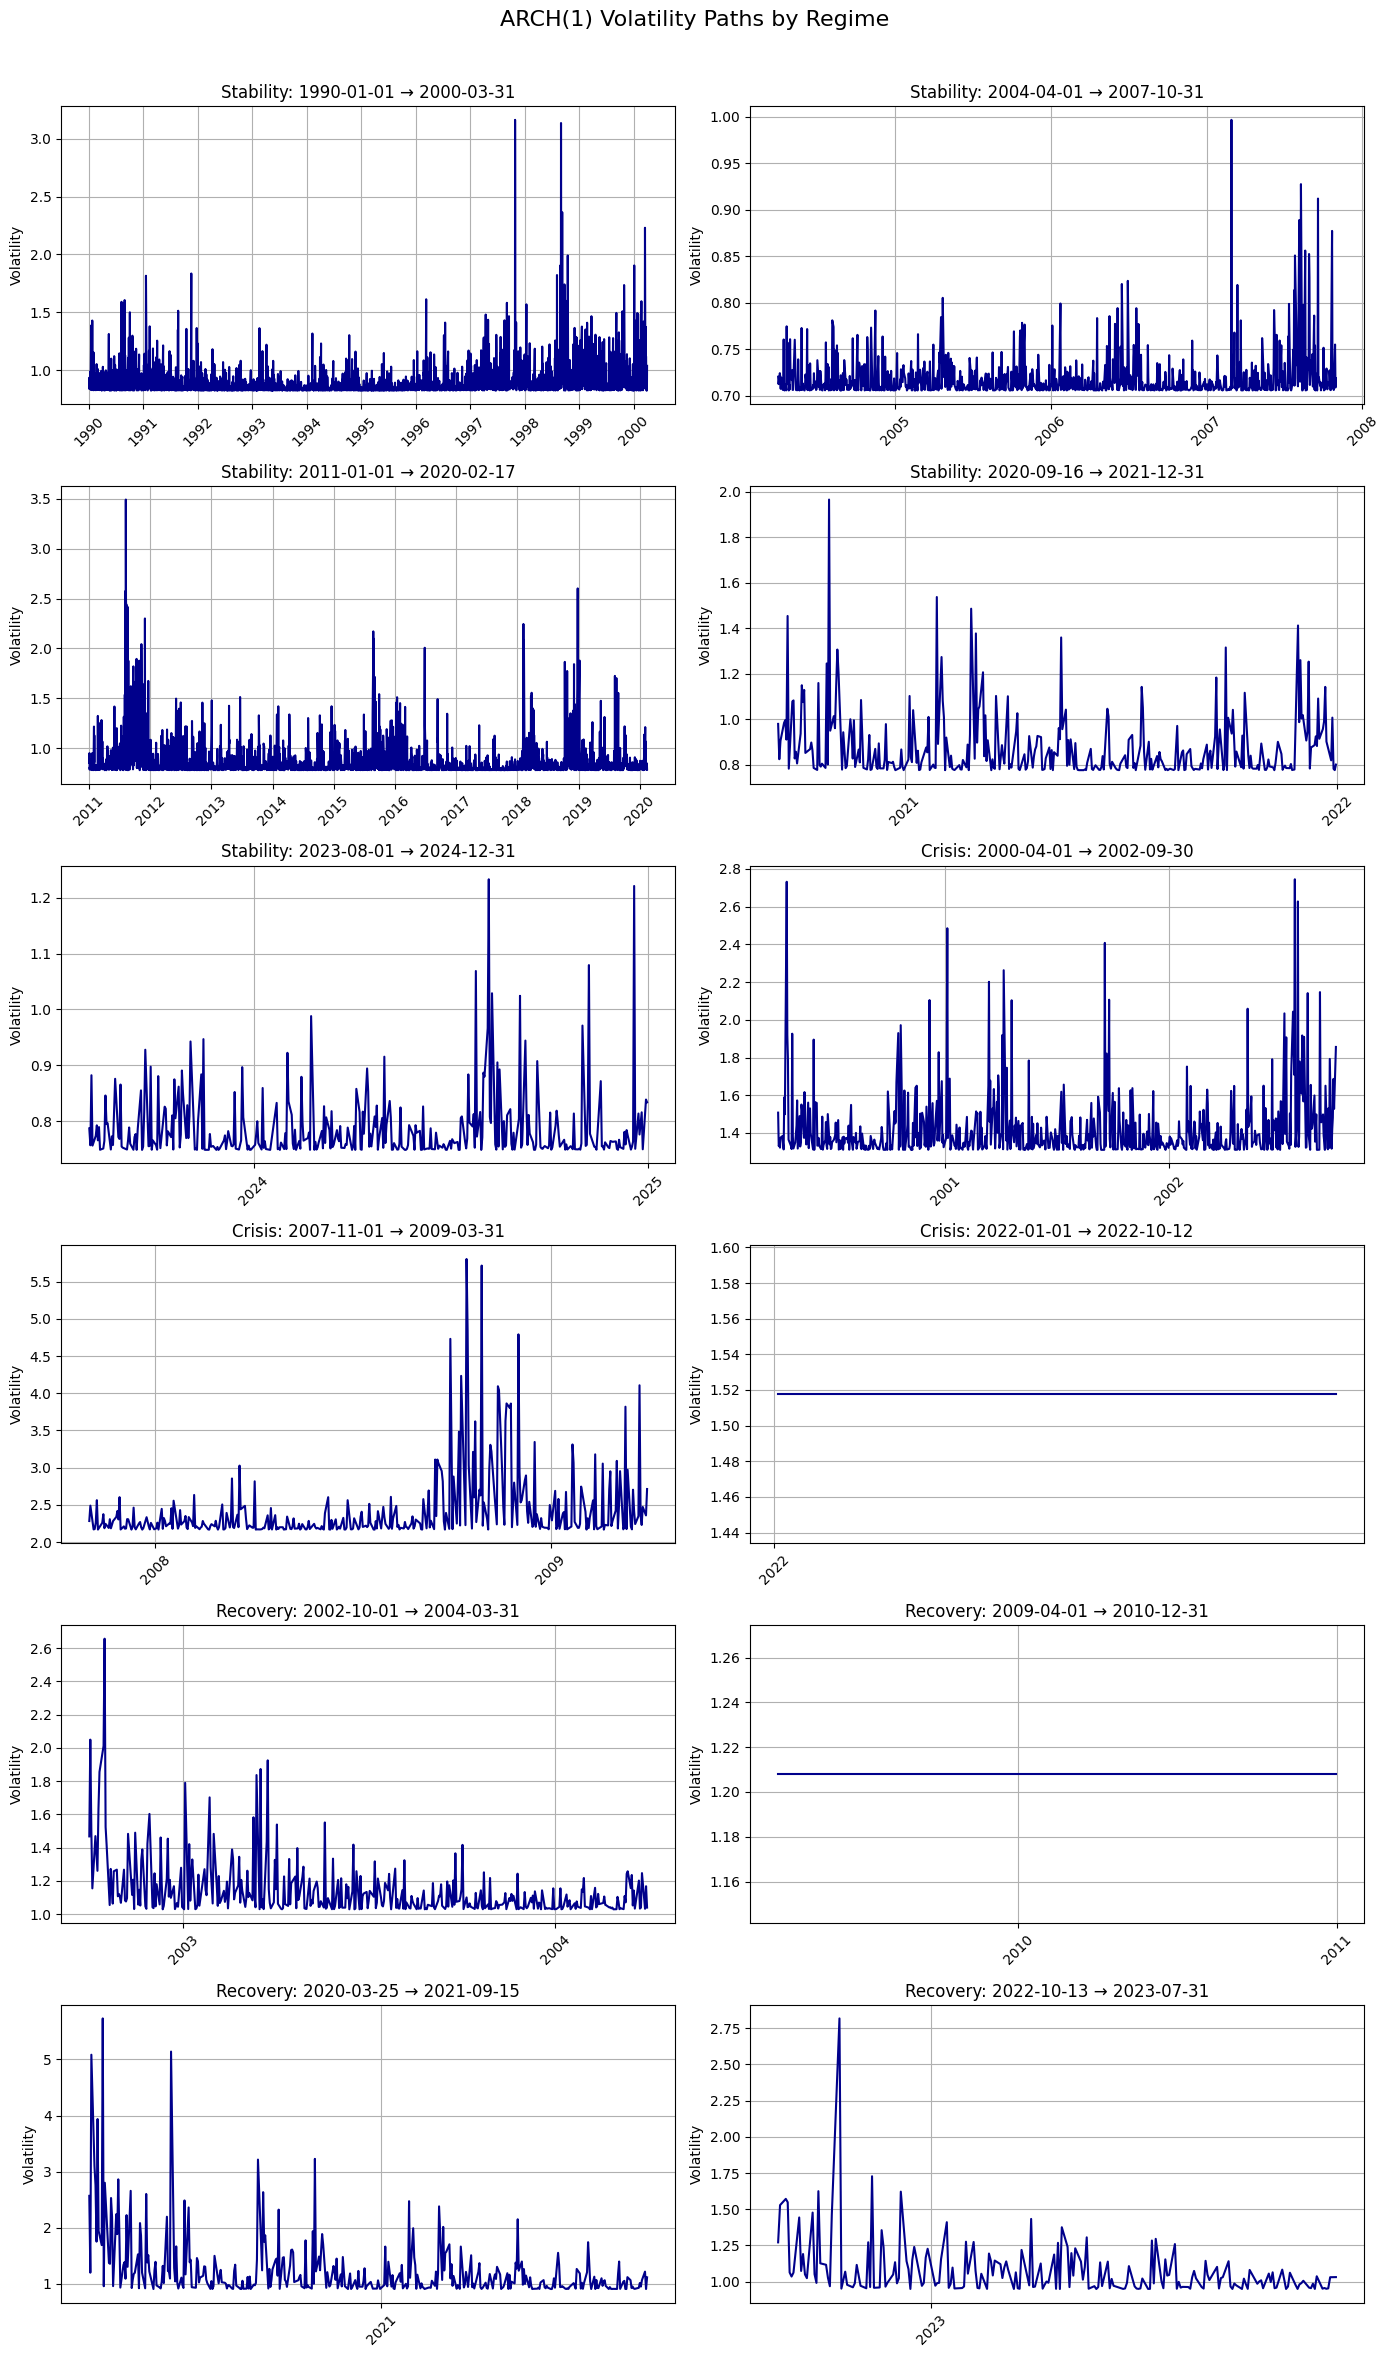

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from arch import arch_model


# === Step 2: Load ARCH(1) parameter estimates ===
#results_df = pd.read_excel(DATA / "ARCH_results_by_period.xlsx")
#results_df = results_df.dropna(subset=["mu", "alpha0", "alpha1"])


# === Step 1: Load return data with regimes ===
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")
df["Return"] = df["SPX Index"].pct_change() * 100
df = df.dropna(subset=["Return"])

# Define regime periods
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]

# Organize for plotting
regimes = ["Stability", "Crisis", "Recovery"]
regime_groups = {r: [] for r in regimes}

# Step 2: Compute volatilities and organize results
for start, end, label in regime_periods:
    start_dt = pd.to_datetime(start)
    end_dt = pd.to_datetime(end)

    returns = df[(df["Date"] >= start_dt) & (df["Date"] <= end_dt)].copy()
    if len(returns) < 100:
        print(f"⚠️ Skipping {label} {start} to {end} — too few returns: {len(returns)}")
        continue

    # Fit ARCH(1) and store volatility path directly
    am = arch_model(returns["Return"], vol='ARCH', p=1, mean='Constant', dist='normal', rescale=False)
    fit = am.fit(disp='off')
    returns["Volatility"] = fit.conditional_volatility
    regime_groups[label].append((start, end, returns))

# Step 3: Setup subplots
ncols = 2
total_plots = sum(len(v) for v in regime_groups.values())
nrows = (total_plots + ncols - 1) // ncols

fig, axs = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
axs = axs.flatten()
plot_idx = 0

# Step 4: Plot each volatility path
for regime in regimes:
    for (start, end, returns) in regime_groups[regime]:
        ax = axs[plot_idx]
        ax.plot(returns["Date"], returns["Volatility"], color="darkblue")
        ax.set_title(f"{regime}: {start[:10]} → {end[:10]}")
        ax.set_ylabel("Volatility")
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        ax.tick_params(axis='x', rotation=45)
        ax.grid(True)
        plot_idx += 1

# Step 5: Clean up unused axes
for i in range(plot_idx, len(axs)):
    axs[i].axis("off")

plt.suptitle("ARCH(1) Volatility Paths by Regime", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()



In [ ]:
#We can group vol by regime as dependencie is only on return --> reset recursion at each period/regime

#We now group data returns by regimes and fit ARCH(1) by regime

#--> Bad result, big cuts bc of periods, not interesting



In [13]:
# Define the two regimes
test_periods = [
    ("2022-01-01", "2022-10-12", "Crisis"), # 0 for alpha1
    ("2009-04-01", "2010-12-31", "Recovery") # 0 for alpha1
    #("2020-03-25",	"2021-09-15", "Recovery") #0.6 alpha1
]

# Loop through each period
for start, end, label in test_periods:
    mask = (df['Date'] >= pd.Timestamp(start)) & (df['Date'] <= pd.Timestamp(end))
    returns = df.loc[mask, 'Return'].dropna()*100

    if len(returns) < 100:
        print("⚠️ Not enough data. Skipping...")
        continue

    am = arch_model(returns, vol='ARCH', p=1, mean='Constant', dist='normal', rescale=False)
    fit = am.fit(disp='off')

    print("Model parameters:")
    print(fit.params)
    #fit.conditional_volatility.plot()

    am_garch = arch_model(returns, vol='GARCH', p=1, q=1, mean='Constant', dist='normal', rescale=False)
    fit_garch = am_garch.fit(disp='off')
    print(fit_garch.params)


Model parameters:
mu            -13.852667
omega       20727.633481
alpha[1]        0.023269
Name: params, dtype: float64
mu           -12.770235
omega       2303.038141
alpha[1]       0.042497
beta[1]        0.861379
Name: params, dtype: float64
Model parameters:
mu          1.111146e+01
omega       1.460068e+04
alpha[1]    2.909243e-17
Name: params, dtype: float64
mu           13.060836
omega       264.534389
alpha[1]      0.089634
beta[1]       0.889741
Name: params, dtype: float64


Skipping Crisis (2020-02-18–2020-03-24) — too few returns: 26
Skipping Stability (2025-01-01–2025-02-20) — too few returns: 34
Skipping Crisis (2025-02-20–2025-04-30) — too few returns: 45


mu               omega              alpha1            \
               mean       std      mean       std      mean       std   
Regime                                                                  
Crisis    -0.099818  0.039363  0.084964  0.038906  0.077025  0.043698   
Recovery   0.115451  0.024001  0.023867  0.028241  0.072806  0.095691   
Stability  0.073257  0.022370  0.056059  0.052710  0.110075  0.078412   

              beta1           persistence            
               mean       std        mean       std  
Regime                                               
Crisis     0.892645  0.024099    0.969670  0.025275  
Recovery   0.905164  0.109911    0.977970  0.014442  
Stability  0.812027  0.129299    0.922102  0.069592

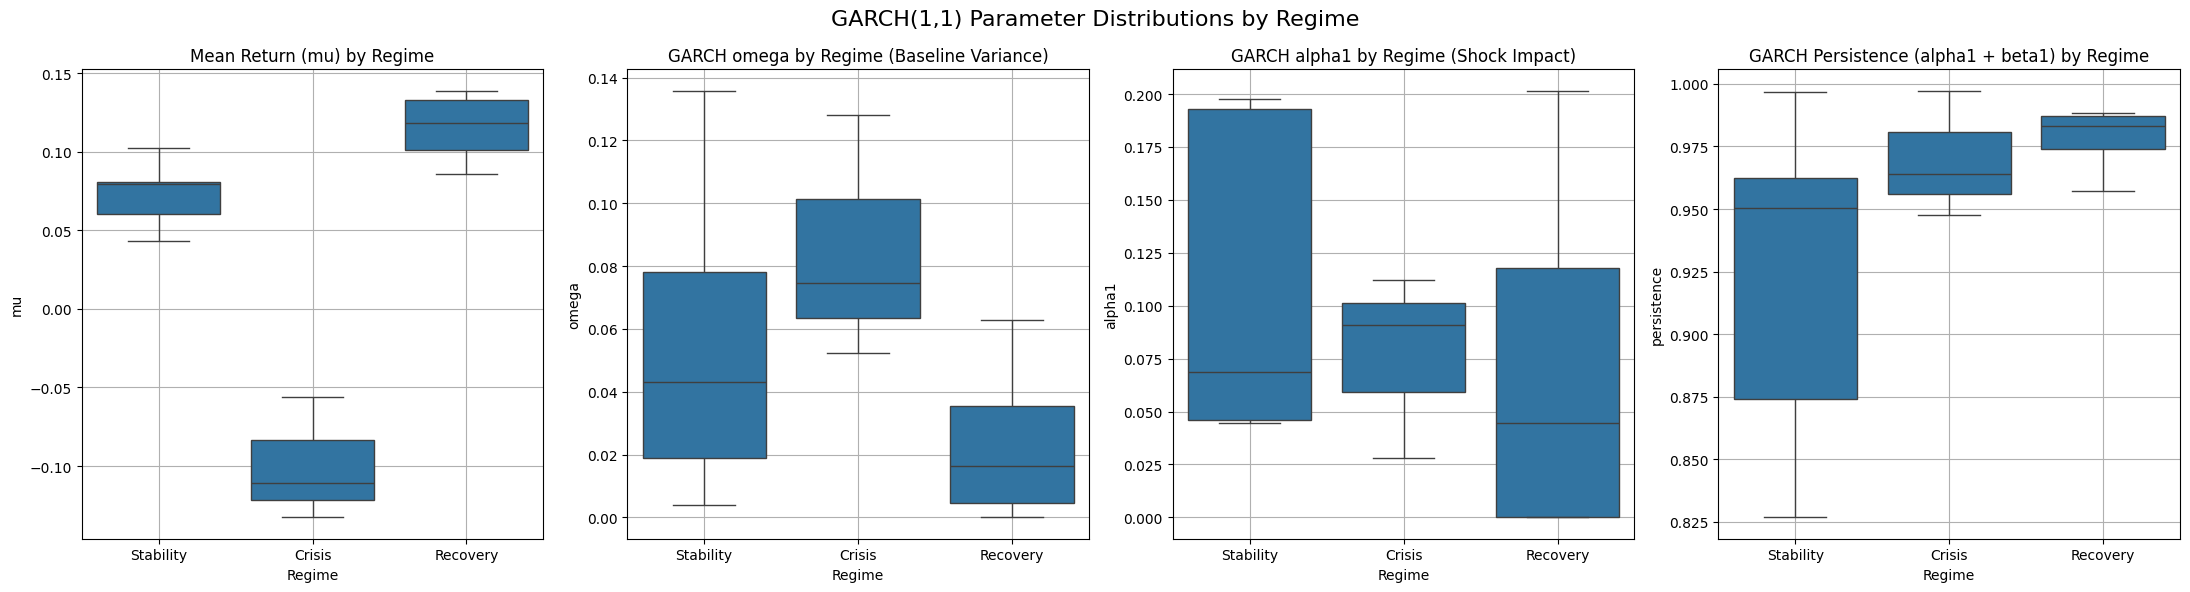

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from arch import arch_model

# Load data with regime labels
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
df['Return'] = df['SPX Index'].pct_change()  * 100
df = df.dropna(subset=['Return'])

# Define regime periods manually
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]

# Fit GARCH(1,1) per regime
results = []
# === Pre-define regime groups as empty lists ===
regimes = ["Stability", "Crisis", "Recovery"]
regime_groups = {regime: [] for regime in regimes}


for start, end, label in regime_periods:
    mask = (df['Date'] >= pd.Timestamp(start)) & (df['Date'] <= pd.Timestamp(end))
    returns = df.loc[mask, 'Return'].dropna() 

    if len(returns) < 100:
        print(f"Skipping {label} ({start}–{end}) — too few returns: {len(returns)}")
        continue

    am = arch_model(returns, vol='GARCH', p=1, q=1, mean='Constant', dist='normal', rescale=False)
    fit = am.fit(disp='off')

    returns["Volatility"] = fit.conditional_volatility
    regime_groups[label].append((start, end, returns))

    params = fit.params

    results.append({
        'Start': start,
        'End': end,
        'Regime': label,
        'mu': params.get('mu', None),
        'omega': params.get('omega', None),
        'alpha1': params.get('alpha[1]', None),
        'beta1': params.get('beta[1]', None),
        'persistence': params.get('alpha[1]', 0) + params.get('beta[1]', 0)
    })

# Compile results
results_df = pd.DataFrame(results)

# Show group stats
group_stats = results_df.groupby("Regime")[["mu", "omega", "alpha1", "beta1", "persistence"]].agg(["mean", "std"])
display(group_stats)

# Plot parameter boxplots by regime
fig, axs = plt.subplots(1, 4, figsize=(22, 6))

sns.boxplot(data=results_df, x="Regime", y="mu", ax=axs[0])
axs[0].set_title("Mean Return (mu) by Regime")
axs[0].grid(True)

sns.boxplot(data=results_df, x="Regime", y="omega", ax=axs[1])
axs[1].set_title("GARCH omega by Regime (Baseline Variance)")
axs[1].grid(True)

sns.boxplot(data=results_df, x="Regime", y="alpha1", ax=axs[2])
axs[2].set_title("GARCH alpha1 by Regime (Shock Impact)")
axs[2].grid(True)

sns.boxplot(data=results_df, x="Regime", y="persistence", ax=axs[3])
axs[3].set_title("GARCH Persistence (alpha1 + beta1) by Regime")
axs[3].grid(True)

plt.suptitle("GARCH(1,1) Parameter Distributions by Regime", fontsize=16)
plt.tight_layout()
plt.show()



⚠️ Skipping Crisis 2020-02-18 to 2020-03-24 — too few returns: 26
⚠️ Skipping Stability 2025-01-01 to 2025-02-20 — too few returns: 34
⚠️ Skipping Crisis 2025-02-20 to 2025-04-30 — too few returns: 45


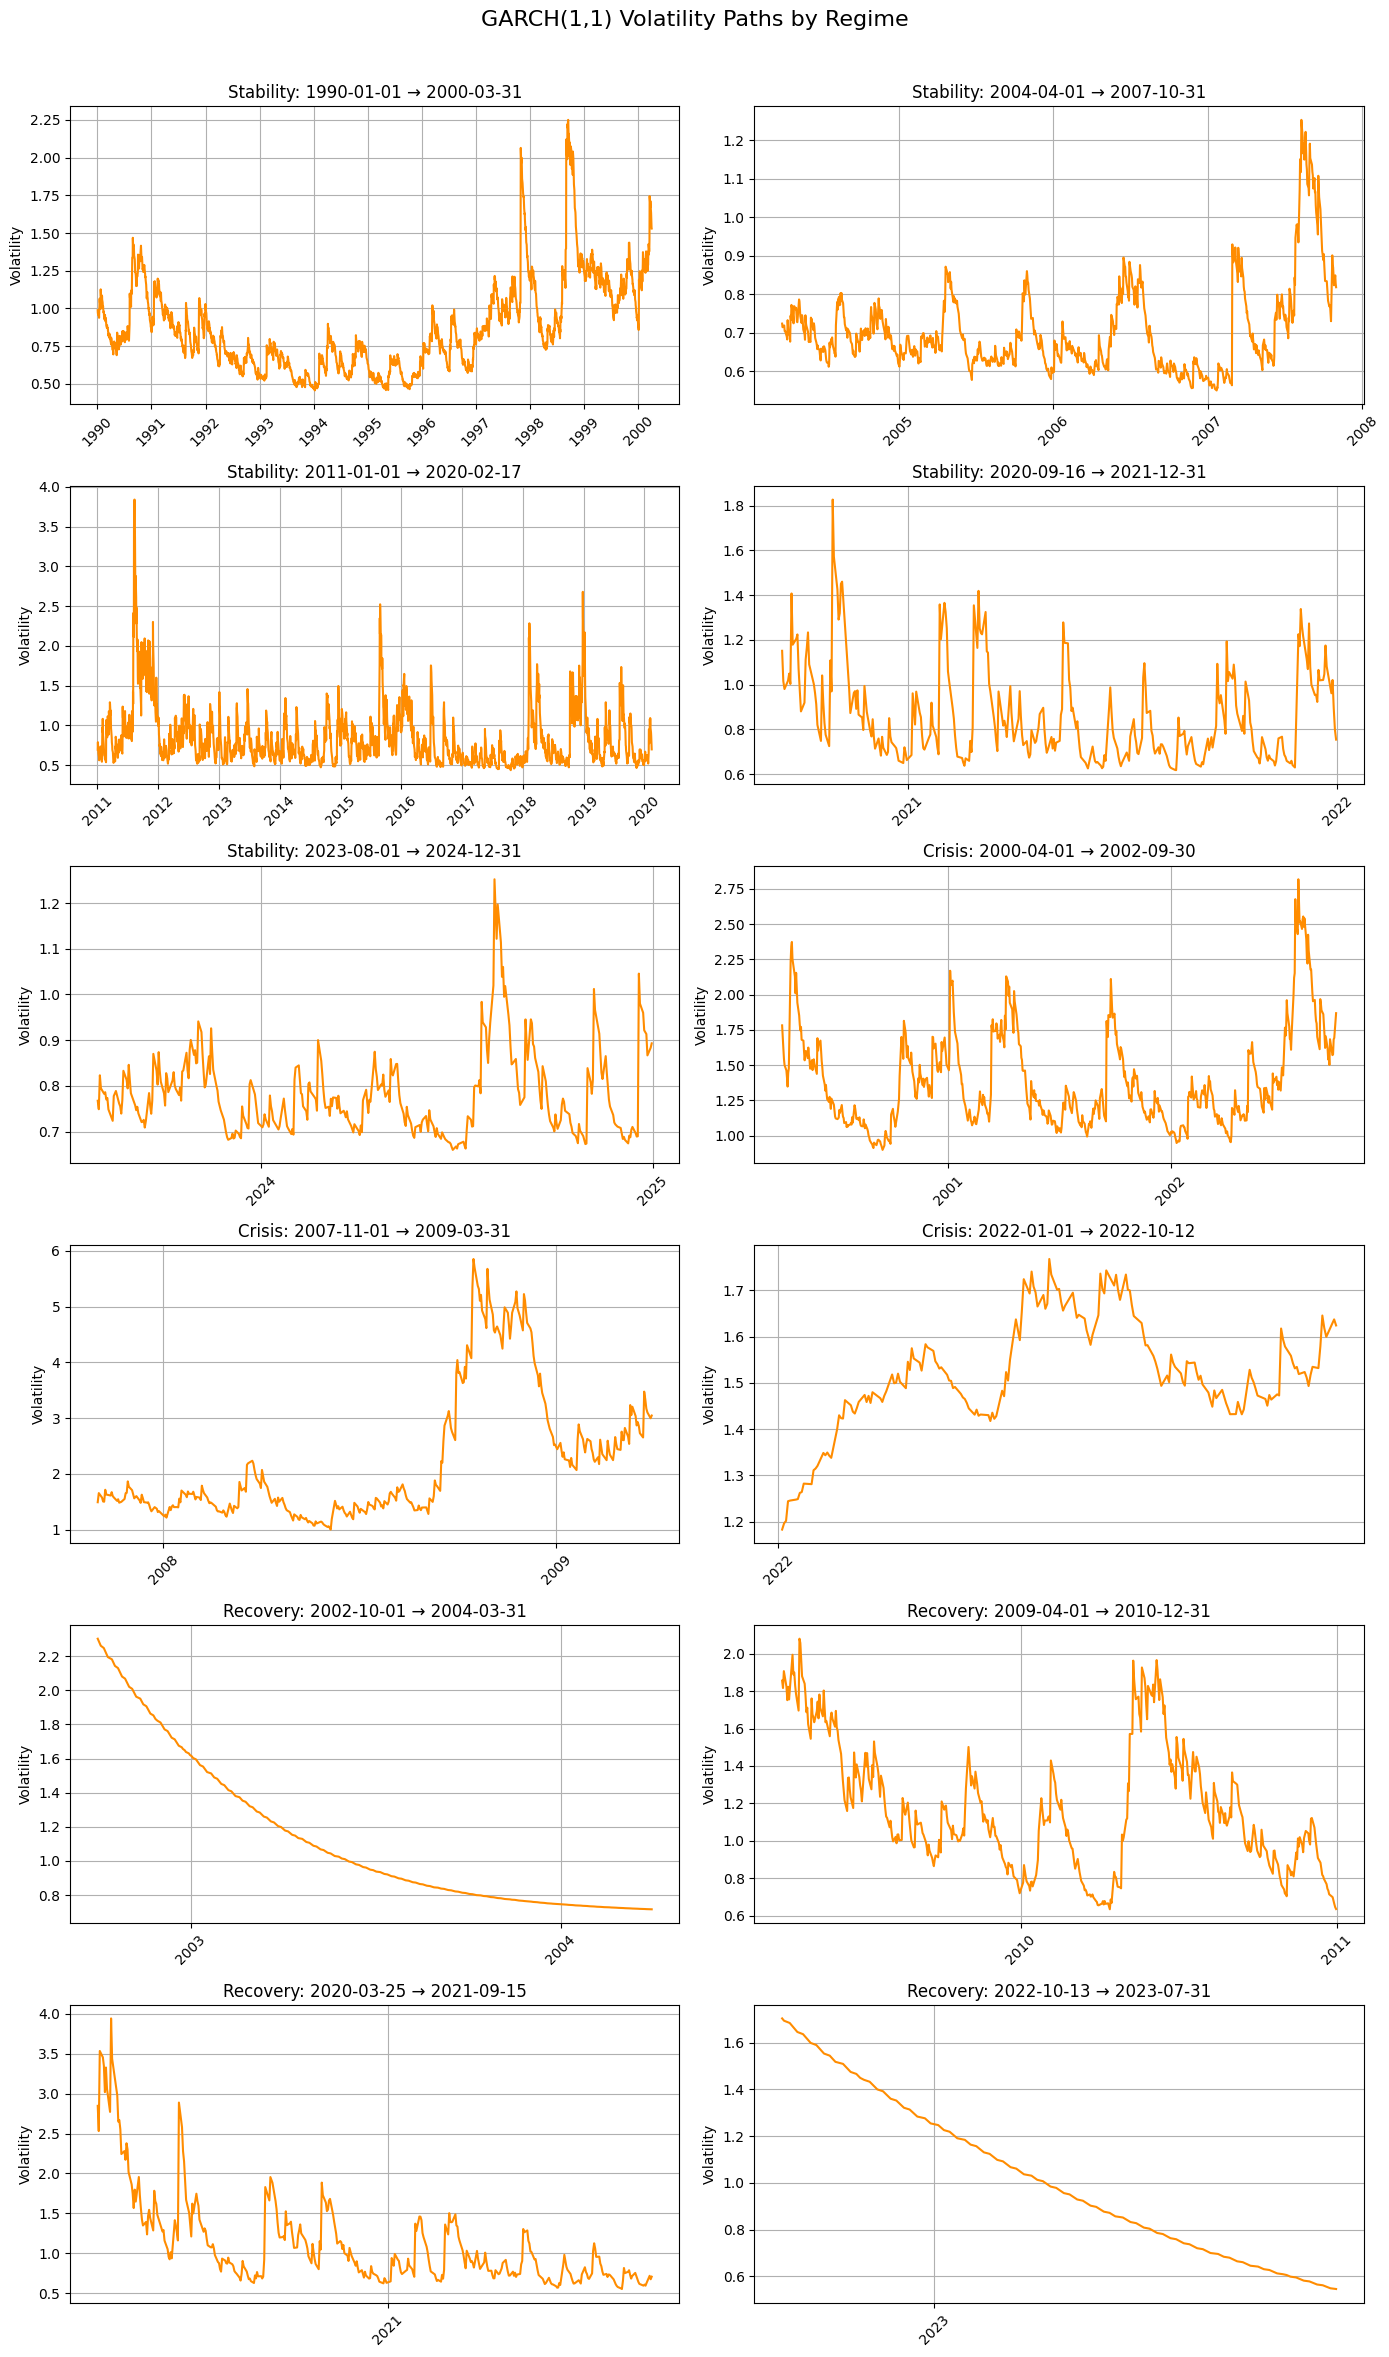

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from arch import arch_model

# === Step 1: Load return data with regimes ===
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")
df["Return"] = df["SPX Index"].pct_change() * 100
df = df.dropna(subset=["Return"])

# Define regime periods
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]

# Organize for plotting
regimes = ["Stability", "Crisis", "Recovery"]
regime_groups = {r: [] for r in regimes}

# Step 2: Compute volatilities and organize results
for start, end, label in regime_periods:
    start_dt = pd.to_datetime(start)
    end_dt = pd.to_datetime(end)

    returns = df[(df["Date"] >= start_dt) & (df["Date"] <= end_dt)].copy()
    if len(returns) < 100:
        print(f"⚠️ Skipping {label} {start} to {end} — too few returns: {len(returns)}")
        continue

    # Fit GARCH(1,1) and store volatility path directly
    am = arch_model(returns["Return"], vol='GARCH', p=1, q=1, mean='Constant', dist='normal', rescale=False)
    fit = am.fit(disp='off')
    returns["Volatility"] = fit.conditional_volatility
    regime_groups[label].append((start, end, returns))

# Step 3: Setup subplots
ncols = 2
total_plots = sum(len(v) for v in regime_groups.values())
nrows = (total_plots + ncols - 1) // ncols

fig, axs = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
axs = axs.flatten()
plot_idx = 0

# Step 4: Plot each volatility path
for regime in regimes:
    for (start, end, returns) in regime_groups[regime]:
        ax = axs[plot_idx]
        ax.plot(returns["Date"], returns["Volatility"], color="darkorange")
        ax.set_title(f"{regime}: {start[:10]} → {end[:10]}")
        ax.set_ylabel("Volatility")
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        ax.tick_params(axis='x', rotation=45)
        ax.grid(True)
        plot_idx += 1

# Step 5: Clean up unused axes
for i in range(plot_idx, len(axs)):
    axs[i].axis("off")

plt.suptitle("GARCH(1,1) Volatility Paths by Regime", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


# We can't do vol by regimes :cross-period dependencies for GARCH violating the assumption that each segment is independent.

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.io as pio
from arch import arch_model

pio.renderers.default = "notebook"

# === Step 1: Load data ===
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")

# === Step 2: Compute % return ===
df["Return"] = df["SPX Index"].pct_change() * 100
df = df.dropna(subset=["Return"])

# === Step 3: Fit GARCH(1,1) to the full return history ===
am = arch_model(df["Return"], vol="GARCH", p=1, q=1, mean="Constant", dist="normal", rescale=False)
fit = am.fit(disp="off")

# === Step 4: Store volatility (same index as returns) ===
df["Volatility"] = fit.conditional_volatility # or fit.conditional_volatility.values but doesn't change if no Nan

# === Step 5: Mark regime blocks ===
df["Regime Shift"] = (df["Regime"] != df["Regime"].shift(1)).astype(int).cumsum()
df["Block ID"] = df["Regime"] + "_" + df["Regime Shift"].astype(str)

# === Step 7: Plotly segmented volatility plot ===
fig = px.line(
    df,
    x="Date",
    y="Volatility",
    color="Regime",
    line_group="Block ID",
    title="GARCH(1,1) Estimated Volatility with Regime Coloring (1990–2025)",
    labels={"Volatility Clean": "Volatility"},
    template="plotly_white"
)

fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Volatility",
    legend_title="Regime",
    hovermode="x unified",
    font=dict(size=14)
)

fig.show()


Mean: -0.05108198830066039
Std Dev: 0.9957452121520504
Skewness: -0.48937820413402316
Kurtosis: 4.9813466900843775


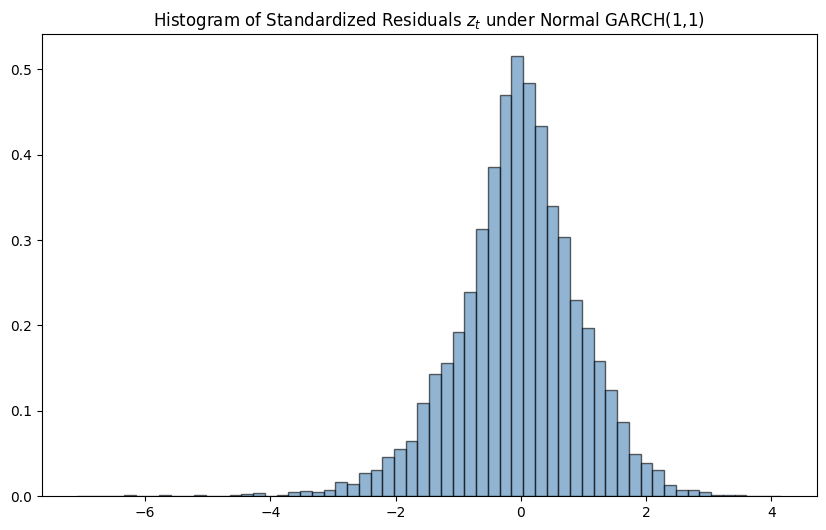

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model

# === Load and prepare data ===
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")
df["Return"] = df["SPX Index"].pct_change() * 100
df = df.dropna(subset=["Return"])

# === Fit GARCH(1,1) with normal innovations ===
am = arch_model(df["Return"], vol="GARCH", p=1, q=1, mean="Constant", dist="studentst", rescale=False)
fit = am.fit(disp="off")

# === Get standardized residuals directly ===
df["z_t"] = fit.std_resid

# === Plot histogram of z_t ===
plt.figure(figsize=(10, 6))
plt.hist(df["z_t"], bins=60, density=True, alpha=0.6, color="steelblue", edgecolor="black")
plt.title("Histogram of Standardized Residuals $z_t$ under Normal GARCH(1,1)")
plt.xlabel

from scipy.stats import skew, kurtosis

z = df["z_t"]

print("Mean:", np.mean(z))
print("Std Dev:", np.std(z))
print("Skewness:", skew(z))
print("Kurtosis:", kurtosis(z, fisher=False))  # Fisher=False gives normal=3



=== Standardized Residual Moments by Regime ===

Regime: Crisis
  Mean     : -0.1683
  Std Dev  : 1.1164
  Skewness : -0.2191
  Kurtosis : 3.8116

Regime: Recovery
  Mean     : 0.0374
  Std Dev  : 0.9880
  Skewness : -0.3435
  Kurtosis : 4.0471

Regime: Stability
  Mean     : -0.0283
  Std Dev  : 0.9744
  Skewness : -0.5433
  Kurtosis : 5.3053



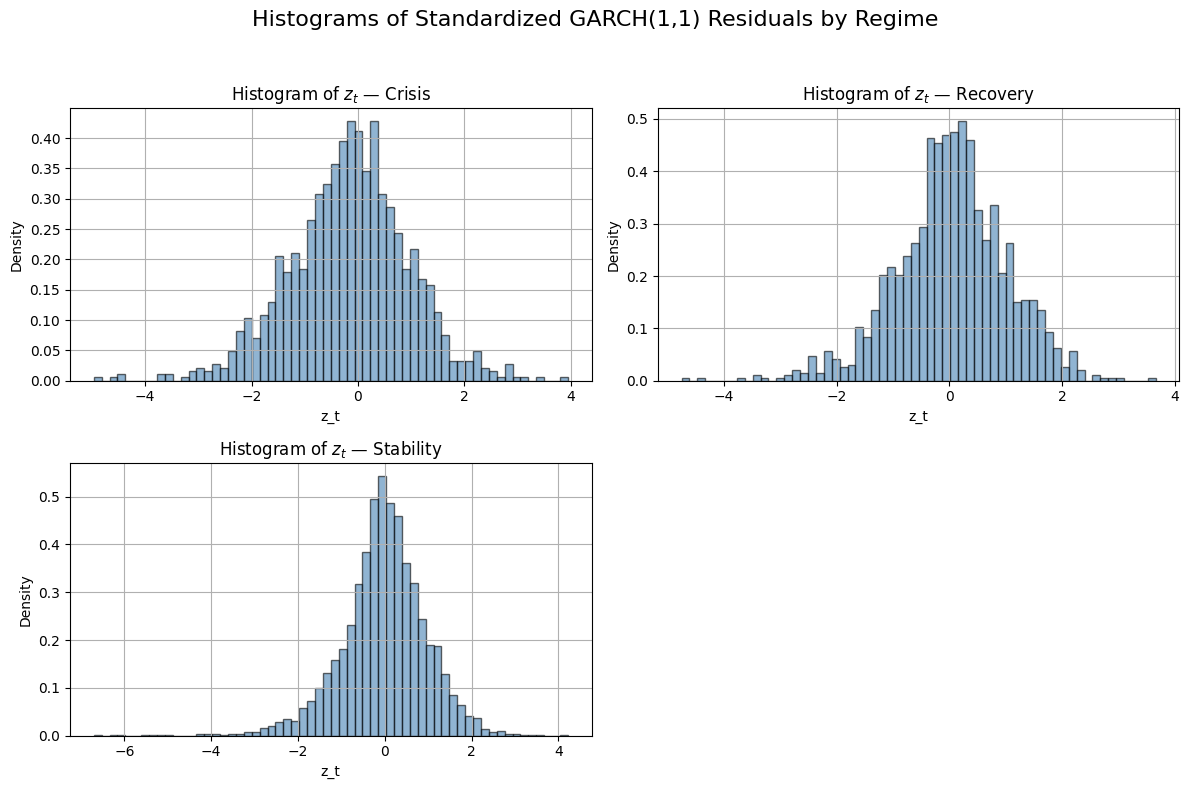

In [ ]:
#Property	Normal Distribution	
#Extreme returns	Very rare	
#Outliers	Few	
#Kurtosis	≈ 3	
#Shape	Bell curve


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model
from scipy.stats import skew, kurtosis

regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]

# Organize for plotting
regimes = ["Stability", "Crisis", "Recovery"]
regime_groups = {r: [] for r in regimes}

# === Step 1: Load SPX returns with regime labels ===
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")

df["Return"] = df["SPX Index"].pct_change() * 100
df = df.dropna(subset=["Return"])

# === Step 2: Fit global GARCH(1,1) ===
am = arch_model(df["Return"], vol="GARCH", p=1, q=1, mean="Constant", dist="Gaussian", rescale=False)
fit = am.fit(disp="off")

# === Step 3: Compute standardized residuals ===
df["z_t"] = fit.std_resid

# === Step 4: Unique regimes ===
regimes = df["Regime"].dropna().unique()
regimes = sorted(regimes)  # optional, to get order: Crisis, Recovery, Stability

# === Step 5: Plot histograms and print moments ===
ncols = 2
nrows = (len(regimes) + 1) // ncols
fig, axs = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axs = axs.flatten()

print("=== Standardized Residual Moments by Regime ===\n")

for i, regime in enumerate(regimes):
    subset = df[df["Regime"] == regime]["z_t"]

    # Moments
    mean = np.mean(subset)
    std = np.std(subset)
    skewness = skew(subset)
    kurt = kurtosis(subset, fisher=False)

    print(f"Regime: {regime}")
    print(f"  Mean     : {mean:.4f}")
    print(f"  Std Dev  : {std:.4f}")
    print(f"  Skewness : {skewness:.4f}")
    print(f"  Kurtosis : {kurt:.4f}\n")

    # Histogram
    ax = axs[i]
    ax.hist(subset, bins=60, density=True, alpha=0.6, color="steelblue", edgecolor="black")
    ax.set_title(f"Histogram of $z_t$ — {regime}")
    ax.set_xlabel("z_t")
    ax.set_ylabel("Density")
    ax.grid(True)

# Turn off any unused subplots
for j in range(i + 1, len(axs)):
    axs[j].axis("off")

plt.suptitle("Histograms of Standardized GARCH(1,1) Residuals by Regime", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### Annex

⚠️ Skipping Crisis 2020-02-18 to 2020-03-24 — too few returns: 26
⚠️ Skipping Stability 2025-01-01 to 2025-02-20 — too few returns: 34
⚠️ Skipping Crisis 2025-02-20 to 2025-04-30 — too few returns: 45


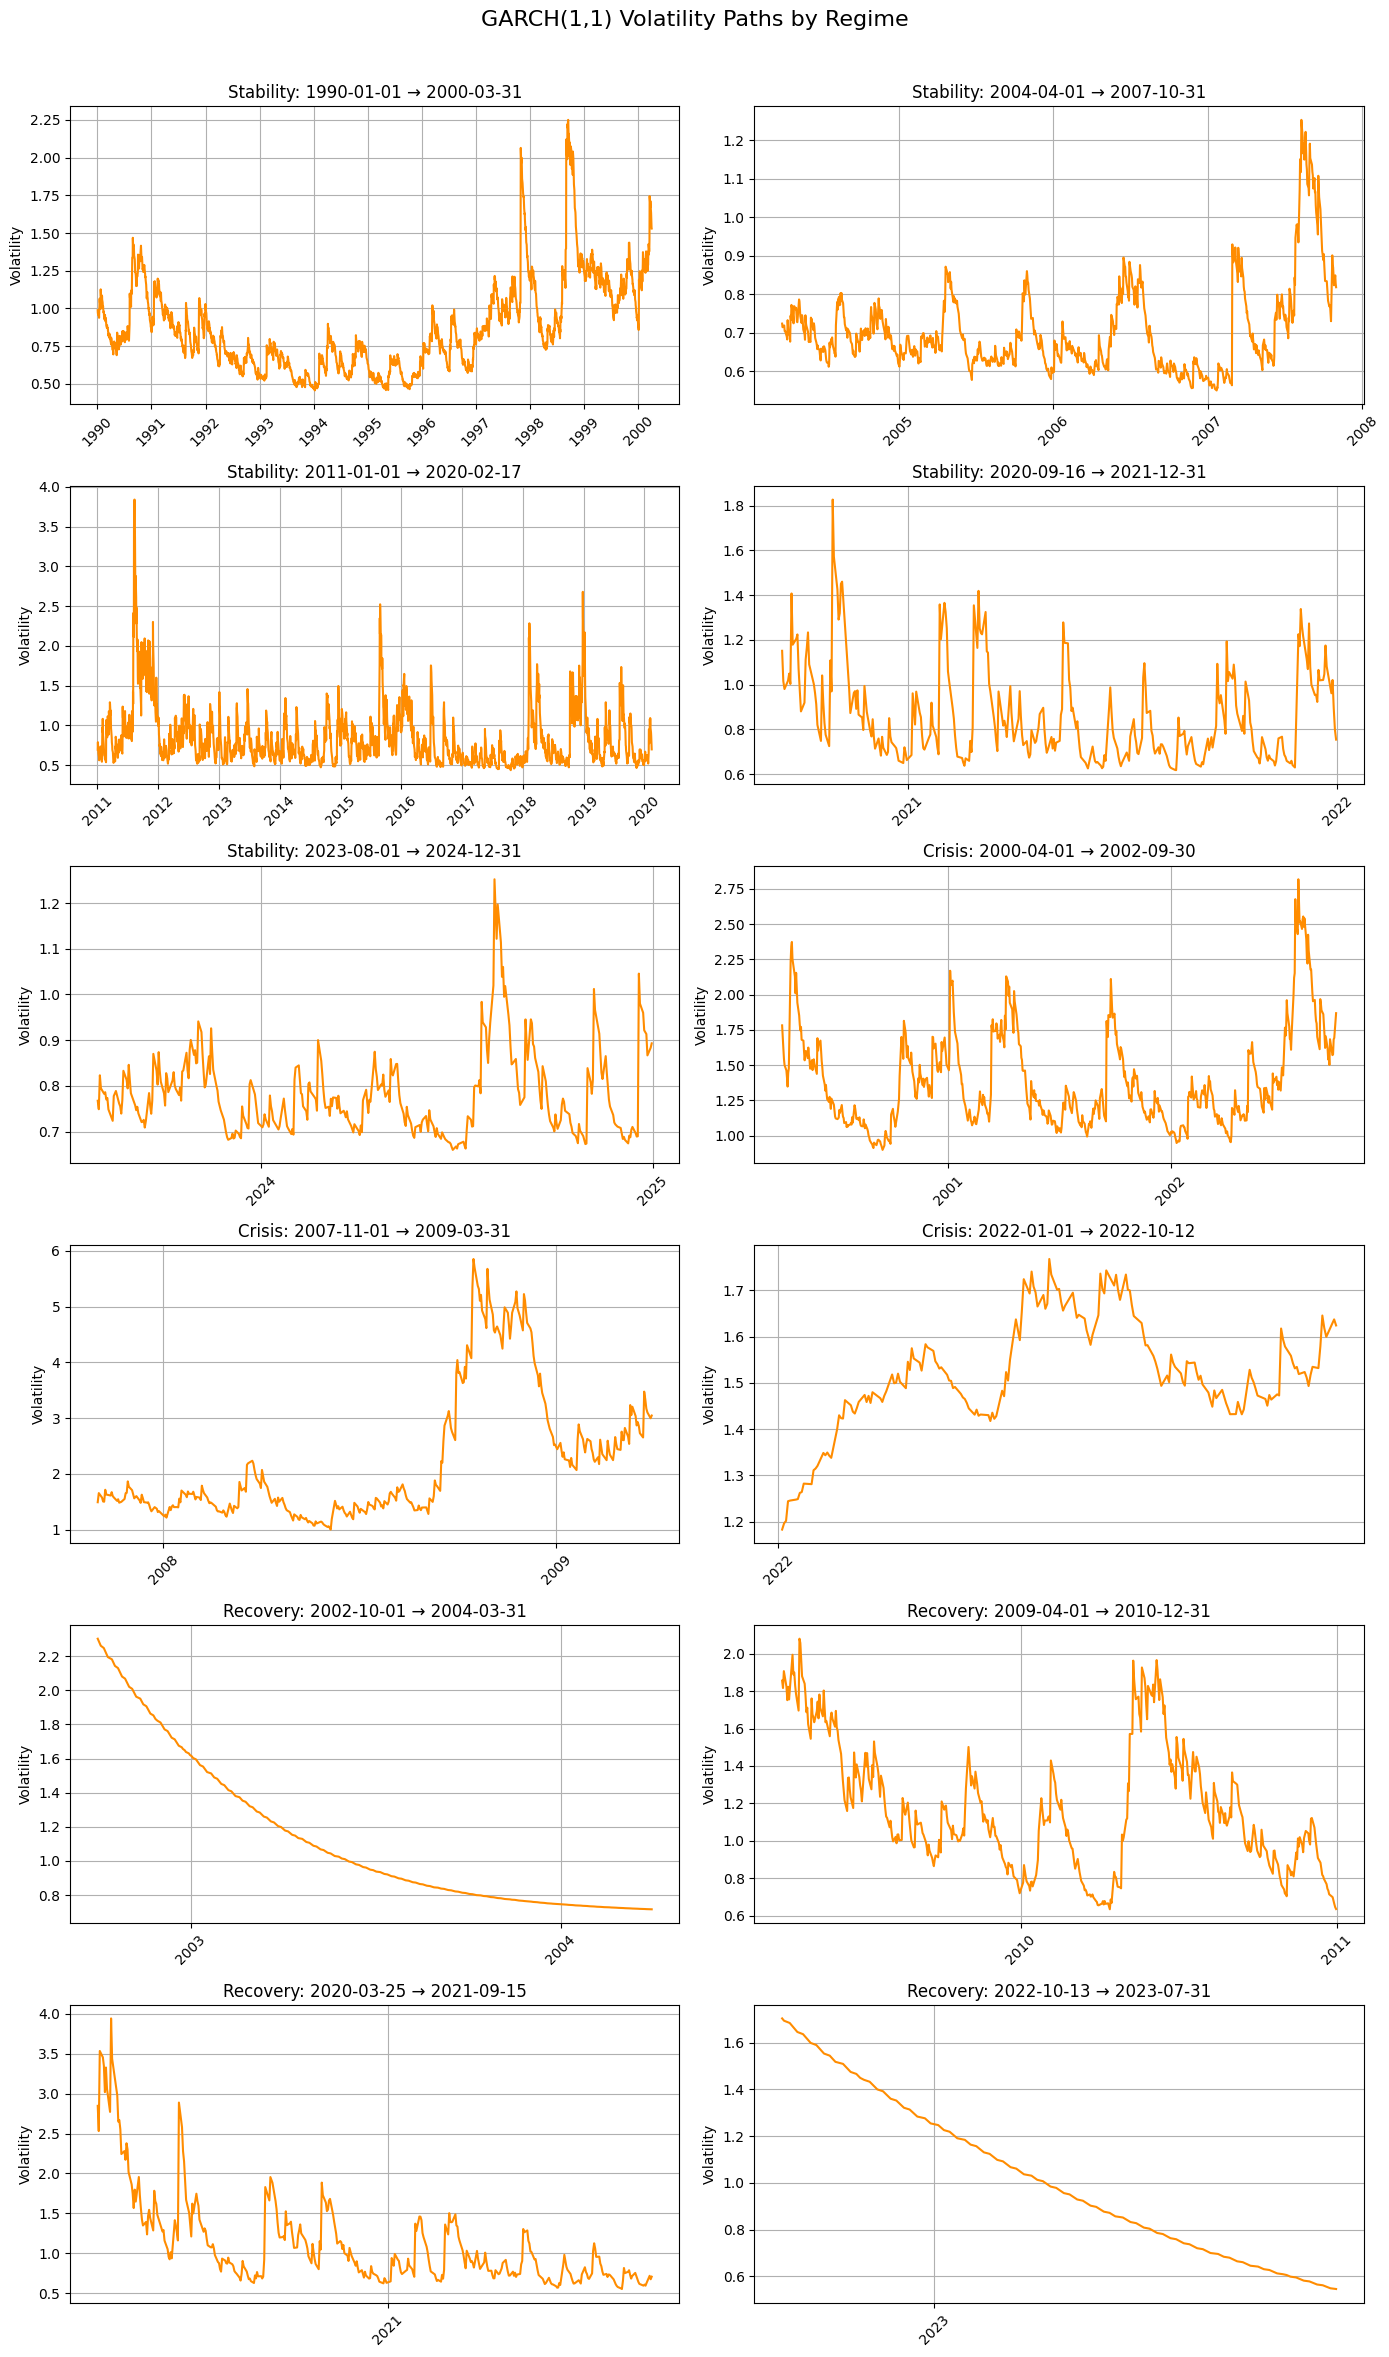

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from arch import arch_model

# === Step 1: Load return data with regimes ===
df = pd.read_excel(DATA / "SPX_with_regimes.xlsx")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")
df["Return"] = df["SPX Index"].pct_change() * 100
df = df.dropna(subset=["Return"])

# Define regime periods
regime_periods = [
    ('1990-01-01', '2000-03-31', 'Stability'),
    ('2000-04-01', '2002-09-30', 'Crisis'),
    ('2002-10-01', '2004-03-31', 'Recovery'),
    ('2004-04-01', '2007-10-31', 'Stability'),
    ('2007-11-01', '2009-03-31', 'Crisis'),
    ('2009-04-01', '2010-12-31', 'Recovery'),
    ('2011-01-01', '2020-02-17', 'Stability'),
    ('2020-02-18', '2020-03-24', 'Crisis'),
    ('2020-03-25', '2021-09-15', 'Recovery'),
    ('2020-09-16', '2021-12-31', 'Stability'),
    ('2022-01-01', '2022-10-12', 'Crisis'),
    ('2022-10-13', '2023-07-31', 'Recovery'),
    ('2023-08-01', '2024-12-31', 'Stability'),
    ('2025-01-01', '2025-02-20', 'Stability'),
    ('2025-02-20', '2025-04-30', 'Crisis'),
]

# Organize for plotting
regimes = ["Stability", "Crisis", "Recovery"]
regime_groups = {r: [] for r in regimes}

# Step 2: Compute volatilities and organize results
for start, end, label in regime_periods:
    start_dt = pd.to_datetime(start)
    end_dt = pd.to_datetime(end)

    returns = df[(df["Date"] >= start_dt) & (df["Date"] <= end_dt)].copy()
    if len(returns) < 100:
        print(f"⚠️ Skipping {label} {start} to {end} — too few returns: {len(returns)}")
        continue

    # Fit GARCH(1,1) and store volatility path directly
    am = arch_model(returns["Return"], vol='GARCH', p=1, q=1, mean='Constant', dist='normal', rescale=False)
    fit = am.fit(disp='off')
    returns["Volatility"] = fit.conditional_volatility
    regime_groups[label].append((start, end, returns))

# Step 3: Setup subplots
ncols = 2
total_plots = sum(len(v) for v in regime_groups.values())
nrows = (total_plots + ncols - 1) // ncols

fig, axs = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
axs = axs.flatten()
plot_idx = 0

# Step 4: Plot each volatility path
for regime in regimes:
    for (start, end, returns) in regime_groups[regime]:
        ax = axs[plot_idx]
        ax.plot(returns["Date"], returns["Volatility"], color="darkorange")
        ax.set_title(f"{regime}: {start[:10]} → {end[:10]}")
        ax.set_ylabel("Volatility")
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        ax.tick_params(axis='x', rotation=45)
        ax.grid(True)
        plot_idx += 1

# Step 5: Clean up unused axes
for i in range(plot_idx, len(axs)):
    axs[i].axis("off")

plt.suptitle("GARCH(1,1) Volatility Paths by Regime", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


# We can't do vol by regimes :cross-period dependencies for GARCH violating the assumption that each segment is independent.

<Axes: xlabel='Date'>

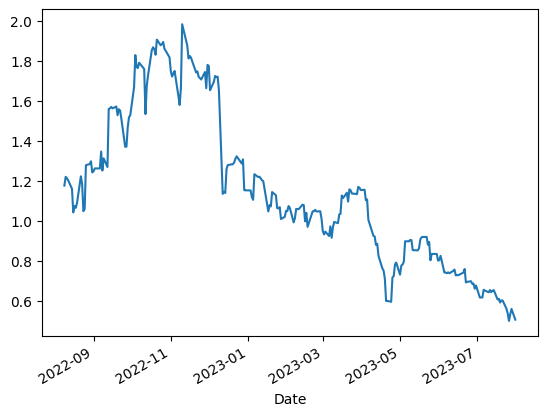

In [78]:
df.set_index('Date').loc['2022-7-13':'2023-07-31']['Return'].rolling(20).std().plot()

In [79]:
df

,Date,SPX Index,VIX Index,CAC Index,Regime,Return
8830,1990-01-03,358.76,18.19,1979.89,Stability,-0.258556
8829,1990-01-04,355.67,19.22,2006.42,Stability,-0.861300
8828,1990-01-05,352.20,20.11,1994.36,Stability,-0.975623
8827,1990-01-08,353.79,20.26,1968.95,Stability,0.451448
8826,1990-01-09,349.62,22.20,1970.28,Stability,-1.178665
...,...,...,...,...,...,...
4,2025-04-17,5282.70,29.65,7285.86,Crisis,0.132684
3,2025-04-21,5158.20,33.82,7285.86,Crisis,-2.356749
2,2025-04-22,5287.76,30.57,7326.47,Crisis,2.511729
1,2025-04-23,5375.86,28.45,7482.36,Crisis,1.666112
